Task 7: Detecting lines and circles

OpenCV 5.0.0
size: (1067, 800, 3) | edge pixels: 9320 (1.1%)


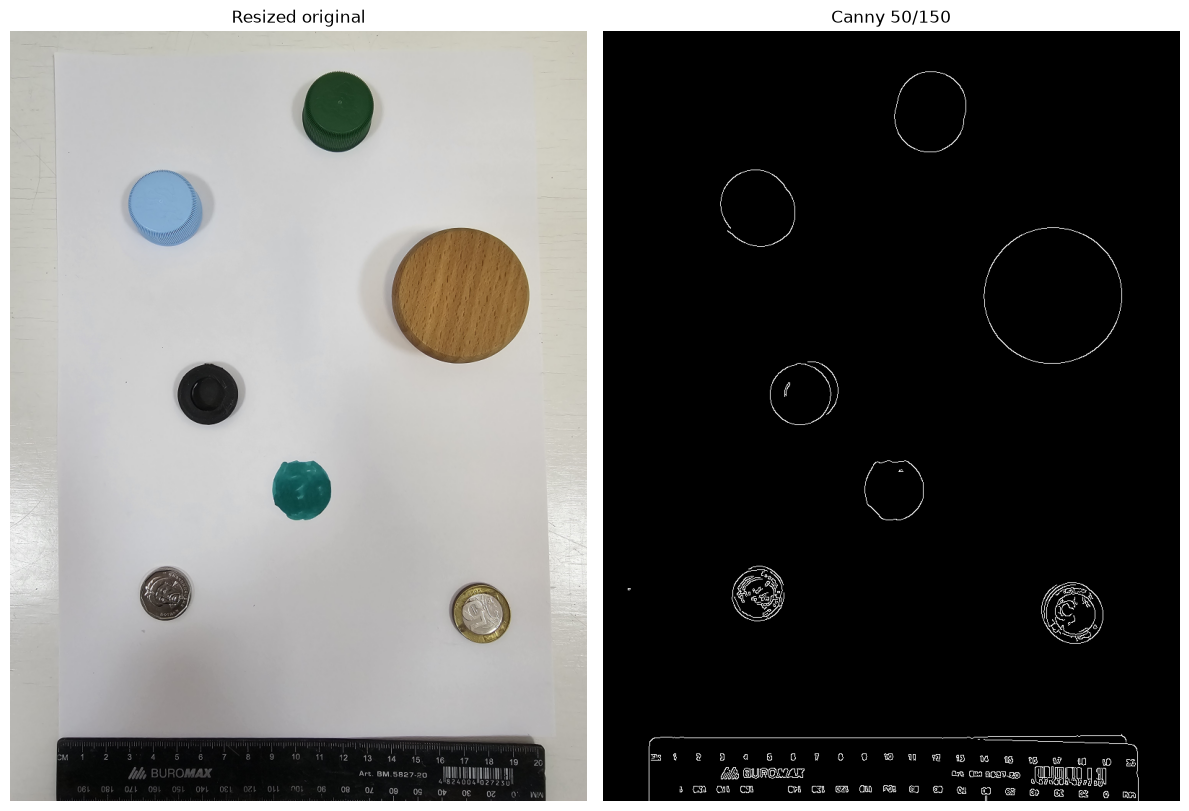

In [4]:
import cv2, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
print("OpenCV", cv2.__version__)

IMAGE_PATH = Path("data") / "task07_shapes.jpg"
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)

img_full = cv2.imread(str(IMAGE_PATH))
assert img_full is not None, f"Cannot read {IMAGE_PATH}"

TARGET_W = 800
scale = TARGET_W / img_full.shape[1]
img = cv2.resize(img_full, (TARGET_W, round(img_full.shape[0] * scale)),
                 interpolation=cv2.INTER_AREA)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

gray_blur = cv2.GaussianBlur(gray, (5, 5), 0)   # input for Canny -> lines
gray_med  = cv2.medianBlur(gray, 5)             # input for HoughCircles (later)

CANNY_LOW, CANNY_HIGH = 50, 150
edges = cv2.Canny(gray_blur, CANNY_LOW, CANNY_HIGH)

n_edge = np.count_nonzero(edges)
print("size:", img.shape, "| edge pixels:", n_edge, f"({100 * n_edge / edges.size:.1f}%)")
cv2.imwrite(str(RESULTS / "task07_edges.png"), edges)

fig, ax = plt.subplots(1, 2, figsize=(12, 8))
ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title("Resized original")
ax[1].imshow(edges, cmap="gray"); ax[1].set_title(f"Canny {CANNY_LOW}/{CANNY_HIGH}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(RESULTS / "task07_step1_edges.png", dpi=120); plt.show()

Canny threshold comparison (part of the experiment)

table mean 200.4 | paper mean 201.6 | step 1.2 grey levels
Canny 50/150                 1.1% edge pixels
Canny 30/90                  1.8% edge pixels
Canny 15/45                  3.3% edge pixels
CLAHE 2.0 + Canny 50/150     1.7% edge pixels


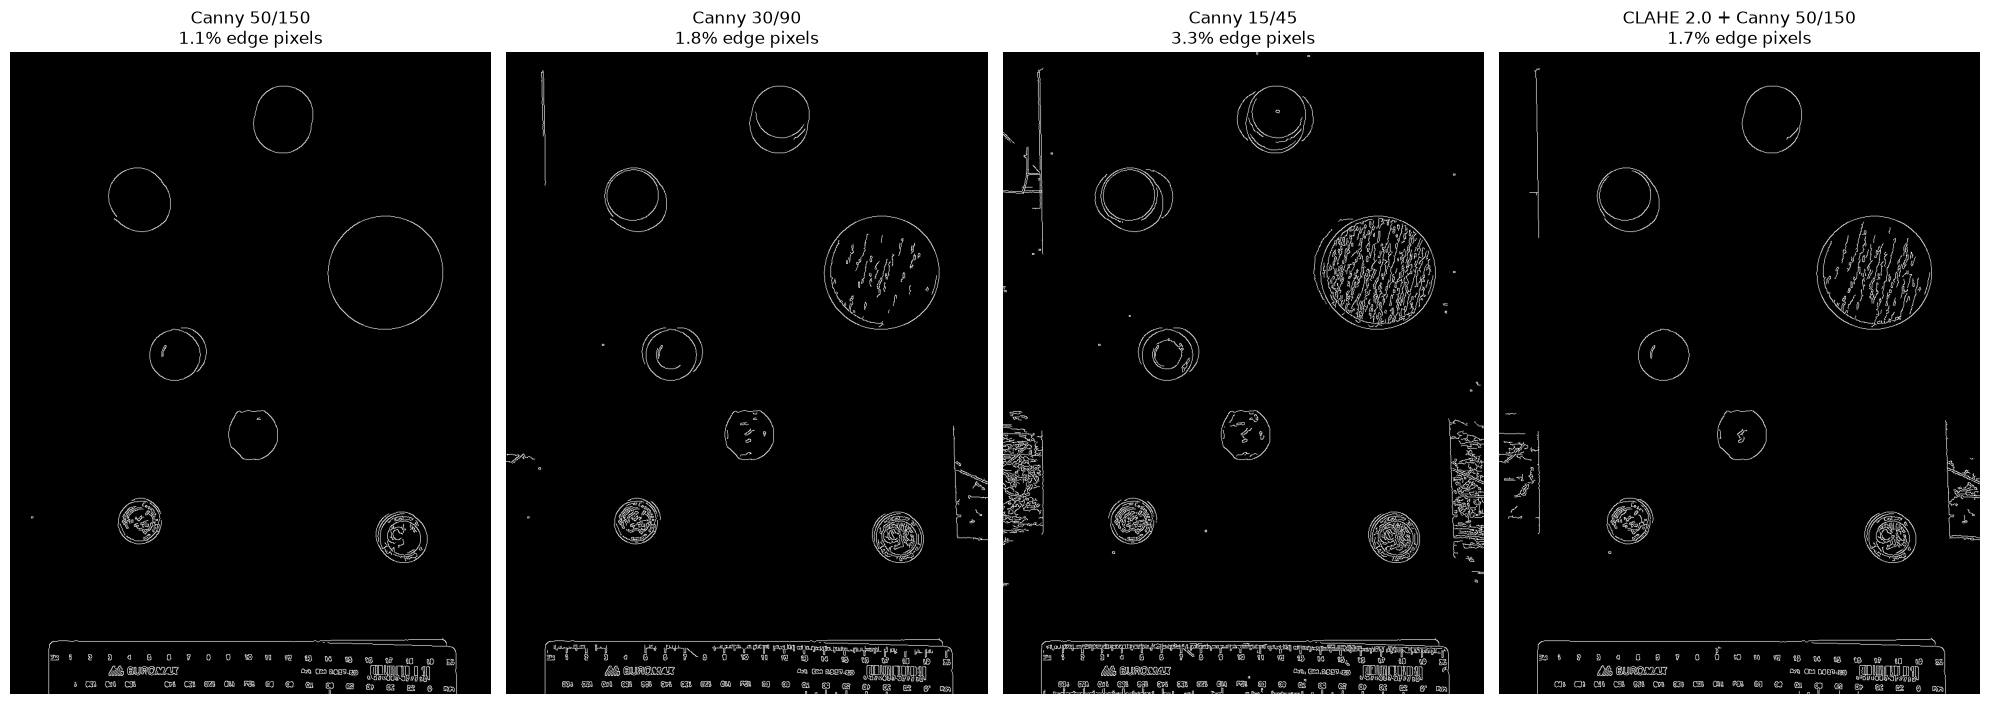

In [5]:
# Step 1b: why the paper edges vanish + Canny threshold comparison
# brightness step across the paper's left edge (paper starts near x ~ 60 in the 800-px image)
table_strip = gray_blur[300:700, 10:40]
paper_strip = gray_blur[300:700, 90:150]
print(f"table mean {table_strip.mean():.1f} | paper mean {paper_strip.mean():.1f} | "
      f"step {paper_strip.mean() - table_strip.mean():.1f} grey levels")

SETTINGS = [(50, 150), (30, 90), (15, 45)]
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
gray_clahe = cv2.GaussianBlur(clahe.apply(gray), (5, 5), 0)

variants = [(f"Canny {lo}/{hi}", cv2.Canny(gray_blur, lo, hi)) for lo, hi in SETTINGS]
variants.append(("CLAHE 2.0 + Canny 50/150", cv2.Canny(gray_clahe, 50, 150)))

fig, ax = plt.subplots(1, 4, figsize=(20, 7))
for a, (name, e) in zip(ax, variants):
    pct = 100 * np.count_nonzero(e) / e.size
    print(f"{name:26s} {pct:5.1f}% edge pixels")
    a.imshow(e, cmap="gray"); a.set_title(f"{name}\n{pct:.1f}% edge pixels"); a.axis("off")
plt.tight_layout(); plt.savefig(RESULTS / "task07_step1b_canny_compare.png", dpi=120); plt.show()

Step 2: HoughLines (standard)

HoughLines threshold=150: 9 lines
 1  rho=  979.0  theta=  90.0 deg  horizontal  (0, 978) -> (799, 979)
 2  rho=  990.0  theta=  90.0 deg  horizontal  (0, 989) -> (799, 990)
 3  rho=  974.0  theta=  92.0 deg  horizontal  (0, 974) -> (799, 1003)
 4  rho= 1054.0  theta=  90.0 deg  horizontal  (0, 1053) -> (799, 1054)
 5  rho=  962.0  theta=  92.0 deg  horizontal  (0, 962) -> (799, 991)
 6  rho=  984.0  theta=  91.0 deg  horizontal  (0, 983) -> (799, 998)
 7  rho=   64.0  theta=   0.0 deg  vertical    (64, 1066) -> (64, 0)
 8  rho=  987.0  theta=  89.0 deg  horizontal  (0, 987) -> (799, 972)
 9  rho=  -61.0  theta= 179.0 deg  vertical    (60, 0) -> (79, 1066)


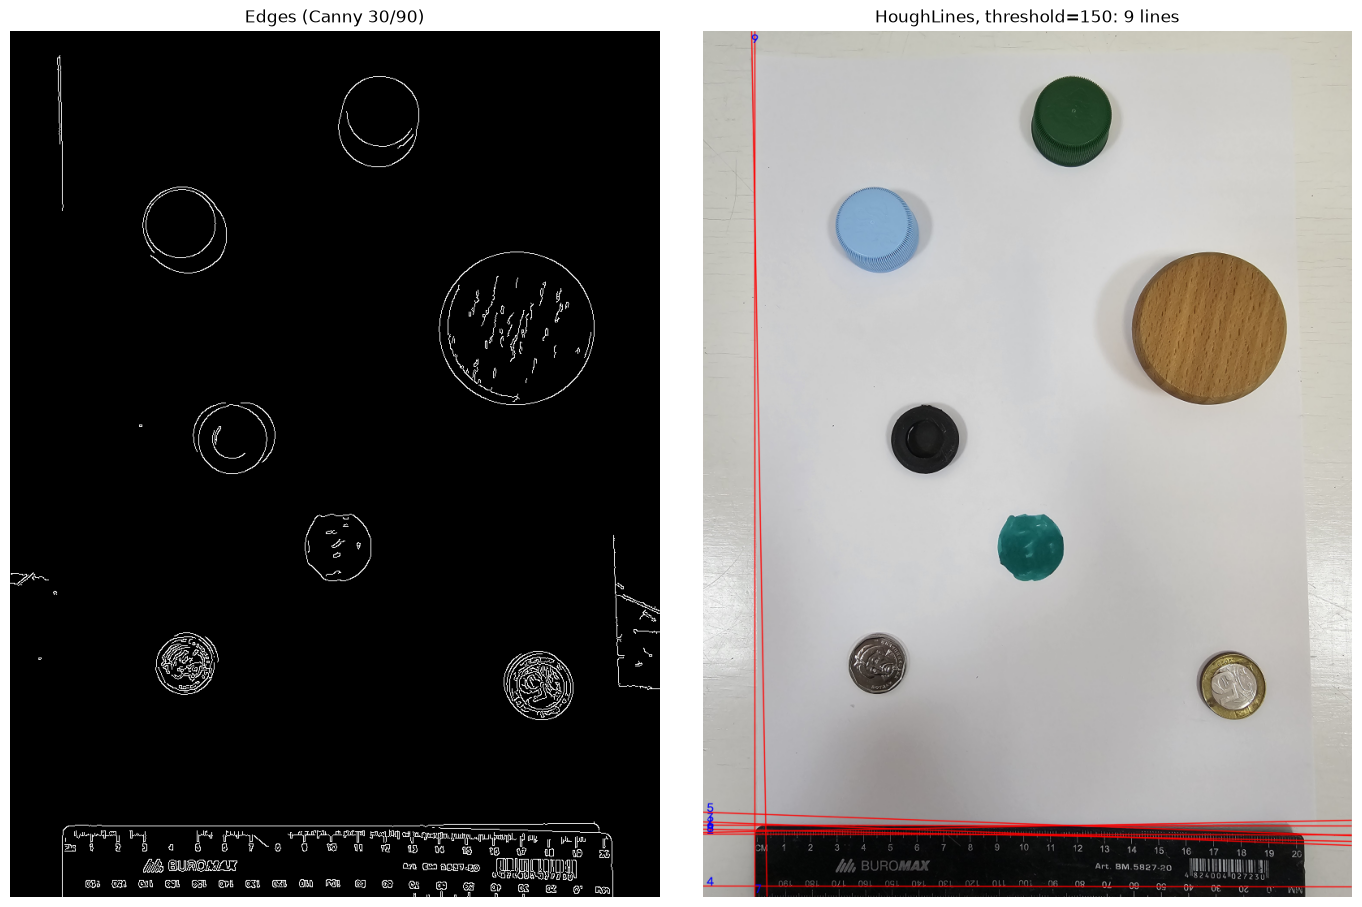

In [6]:
import csv

LOW, HIGH = 30, 90                      # chosen in Step 1b
EDGES = cv2.Canny(gray_blur, LOW, HIGH)
cv2.imwrite(str(RESULTS / "task07_edges.png"), EDGES)   # final edge map used for lines

H_img, W_img = EDGES.shape

def hough_lines(edges, threshold):
    """Return list of (rho, theta) or [] if nothing found."""
    res = cv2.HoughLines(edges, 1, np.pi / 180, threshold)
    return [] if res is None else [(float(r), float(t)) for r, t in res[:, 0]]

def line_endpoints(rho, theta, L=3000):
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho            # foot of the perpendicular from (0,0)
    return (int(x0 - L * b), int(y0 + L * a)), (int(x0 + L * b), int(y0 - L * a))

def line_kind(deg):
    if abs(deg - 90) < 10: return "horizontal"
    if deg < 10 or deg > 170: return "vertical"
    return "oblique"

HL_THRESHOLD = 150
lines = hough_lines(EDGES, HL_THRESHOLD)
print(f"HoughLines threshold={HL_THRESHOLD}: {len(lines)} lines")

vis_hl = img.copy()
rows = []
for i, (rho, theta) in enumerate(lines, 1):
    p1, p2 = line_endpoints(rho, theta)
    ok, q1, q2 = cv2.clipLine((0, 0, W_img, H_img), p1, p2)   # visible part only
    if not ok:
        continue
    cv2.line(vis_hl, q1, q2, (0, 0, 255), 1, cv2.LINE_AA)
    cv2.putText(vis_hl, str(i), (min(max(q1[0], 5), W_img - 25), min(max(q1[1], 15), H_img - 5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1, cv2.LINE_AA)
    deg = np.degrees(theta)
    rows.append([i, round(rho, 1), round(deg, 1), line_kind(deg), q1, q2])
    print(f"{i:2d}  rho={rho:7.1f}  theta={deg:6.1f} deg  {line_kind(deg):10s}  {q1} -> {q2}")

cv2.imwrite(str(RESULTS / "task07_hough_lines.png"), vis_hl)
with open(RESULTS / "task07_lines.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["id", "rho", "theta_deg", "kind", "p1_visible", "p2_visible"])
    w.writerows(rows)

fig, ax = plt.subplots(1, 2, figsize=(14, 9))
ax[0].imshow(EDGES, cmap="gray"); ax[0].set_title(f"Edges (Canny {LOW}/{HIGH})")
ax[1].imshow(cv2.cvtColor(vis_hl, cv2.COLOR_BGR2RGB))
ax[1].set_title(f"HoughLines, threshold={HL_THRESHOLD}: {len(lines)} lines")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(RESULTS / "task07_step2_hough_lines.png", dpi=120); plt.show()

Step 3: HoughLinesP (probabilistic, segments)

HoughLinesP threshold=50, minLineLength=50, maxLineGap=10: 86 segments
 1  ( 97, 979) -> (514, 979)  len= 417.0  angle=  0.0  horizontal
 2  (343, 990) -> (618, 990)  len= 275.0  angle=  0.0  horizontal
 3  (410, 991) -> (618, 991)  len= 208.0  angle=  0.0  horizontal
 4  (446, 992) -> (648, 992)  len= 202.0  angle=  0.0  horizontal
 5  (743, 621) -> (750, 807)  len= 186.1  angle= 87.8  vertical
 6  (401, 989) -> (559, 989)  len= 158.0  angle=  0.0  horizontal
 7  (493, 993) -> (648, 993)  len= 155.0  angle=  0.0  horizontal
 8  (510, 994) -> (647, 996)  len= 137.0  angle=  0.8  horizontal
 9  (401, 988) -> (532, 988)  len= 131.0  angle=  0.0  horizontal
10  (534, 977) -> (661, 977)  len= 127.0  angle=  0.0  horizontal
11  (164,1032) -> (279,1022)  len= 115.4  angle=175.0  horizontal
12  (164,1033) -> (278,1025)  len= 114.3  angle=176.0  horizontal
13  (164,1035) -> (277,1027)  len= 113.3  angle=176.0  horizontal
14  (164,1036) -> (276,1029)  len= 112.2  angle=176.4  horizontal
15  (40

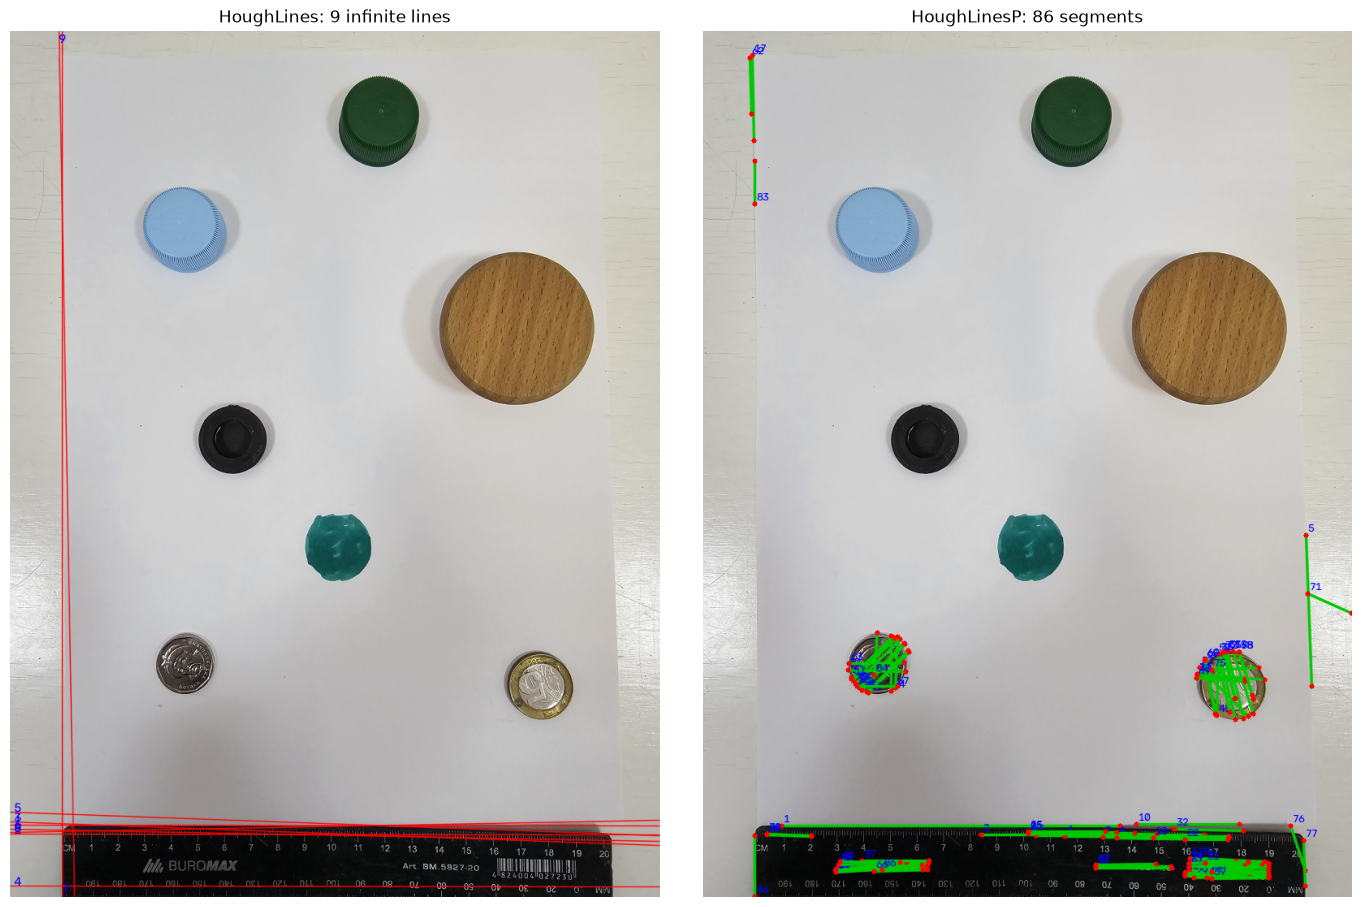

In [11]:
P_THRESHOLD, MIN_LEN, MAX_GAP = 50, 50, 10

def hough_segments(edges, threshold, min_len, max_gap):
    """Return list of (x1, y1, x2, y2) or [] if nothing found.
    reshape(-1, 4) works for both layouts: OpenCV 4.x (N,1,4) and OpenCV 5.0 (N,4)."""
    res = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold,
                          minLineLength=min_len, maxLineGap=max_gap)
    if res is None:
        return []
    return [tuple(int(v) for v in s) for s in res.reshape(-1, 4)]
def seg_kind(ang):
    if ang < 10 or ang > 170: return "horizontal"
    if abs(ang - 90) < 10:    return "vertical"
    return "oblique"

segs = hough_segments(EDGES, P_THRESHOLD, MIN_LEN, MAX_GAP)
segs = sorted(segs, key=lambda s: -np.hypot(s[2] - s[0], s[3] - s[1]))   # longest first
print(f"HoughLinesP threshold={P_THRESHOLD}, minLineLength={MIN_LEN}, maxLineGap={MAX_GAP}: "
      f"{len(segs)} segments")

vis_p = img.copy()
rows_p = []
for i, (x1, y1, x2, y2) in enumerate(segs, 1):
    length = np.hypot(x2 - x1, y2 - y1)
    ang = np.degrees(np.arctan2(y2 - y1, x2 - x1)) % 180
    cv2.line(vis_p, (x1, y1), (x2, y2), (0, 200, 0), 2, cv2.LINE_AA)
    cv2.circle(vis_p, (x1, y1), 3, (0, 0, 255), -1); cv2.circle(vis_p, (x2, y2), 3, (0, 0, 255), -1)
    cv2.putText(vis_p, str(i), (x1 + 3, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 0, 0), 1, cv2.LINE_AA)
    rows_p.append([i, x1, y1, x2, y2, round(length, 1), round(ang, 1), seg_kind(ang)])
    print(f"{i:2d}  ({x1:3d},{y1:4d}) -> ({x2:3d},{y2:4d})  len={length:6.1f}  angle={ang:5.1f}  {seg_kind(ang)}")

cv2.imwrite(str(RESULTS / "task07_hough_lines_p.png"), vis_p)
with open(RESULTS / "task07_lines_p.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["id", "x1", "y1", "x2", "y2", "length_px", "angle_deg", "kind"])
    w.writerows(rows_p)

fig, ax = plt.subplots(1, 2, figsize=(14, 9))
ax[0].imshow(cv2.cvtColor(vis_hl, cv2.COLOR_BGR2RGB)); ax[0].set_title(f"HoughLines: {len(lines)} infinite lines")
ax[1].imshow(cv2.cvtColor(vis_p, cv2.COLOR_BGR2RGB)); ax[1].set_title(f"HoughLinesP: {len(segs)} segments")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(RESULTS / "task07_step3_hough_lines_p.png", dpi=120); plt.show()

In [12]:
r = cv2.HoughLinesP(EDGES, 1, np.pi/180, P_THRESHOLD, minLineLength=MIN_LEN, maxLineGap=MAX_GAP)
print("HoughLinesP shape:", None if r is None else r.shape)
print("HoughLines  shape:", cv2.HoughLines(EDGES, 1, np.pi/180, HL_THRESHOLD).shape)

HoughLinesP shape: (86, 4)
HoughLines  shape: (9, 1, 2)


Step 3b: Classifying segments as true or false

per category: {'ruler_top': 16, 'paper_right': 1, 'FALSE_ruler_text': 31, 'paper_left': 3, 'FALSE_other': 34, 'ruler_end': 1}
segments: 86 | on true lines: 21 | false: 65
true lines found: 4/7 -> ['paper_left', 'paper_right', 'ruler_end', 'ruler_top']
missed: ['paper_top', 'ruler_bottom', 'ruler_left']
duplicates (extra segments on found lines): 17


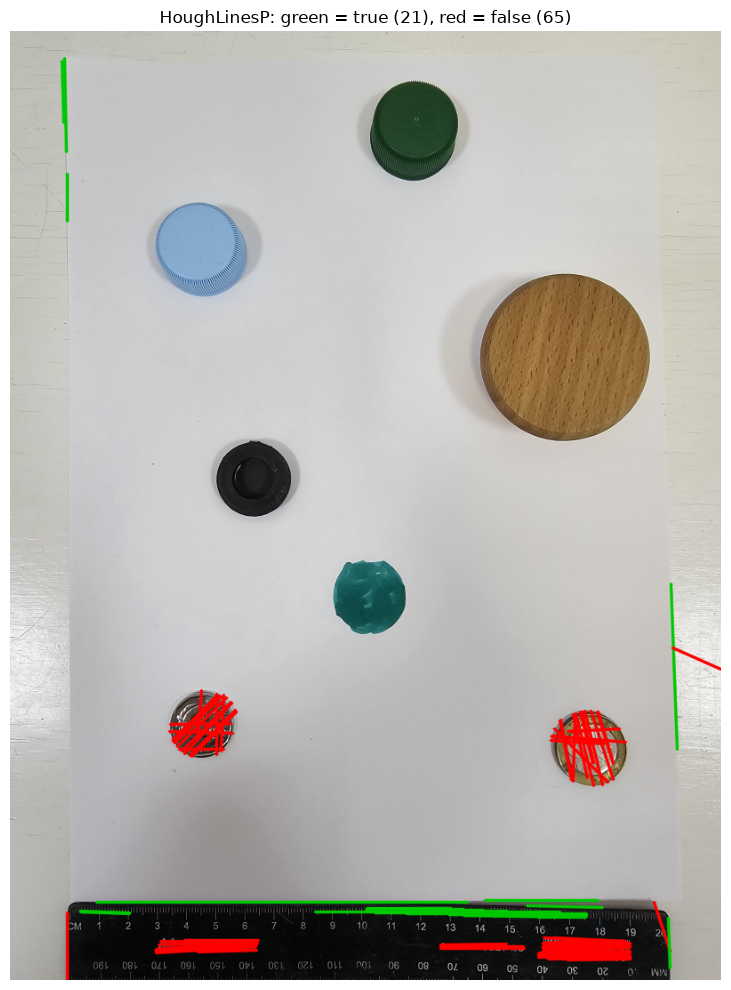

In [14]:
from collections import Counter

#GT_LINES = ["paper_top", "paper_left", "paper_right", "ruler_top", "ruler_bottom", "ruler_end"]
GT_LINES = ["paper_top", "paper_left", "paper_right", "ruler_top", "ruler_bottom", "ruler_left", "ruler_end"]
def seg_category(x1, y1, x2, y2):
    """Assign a segment to a true line (by region + orientation) or to FALSE."""
    ang = np.degrees(np.arctan2(y2 - y1, x2 - x1)) % 180
    kind = seg_kind(ang)
    xmin, xmax, ymin, ymax = min(x1, x2), max(x1, x2), min(y1, y2), max(y1, y2)
    if kind == "horizontal" and ymax < 40:                    return "paper_top"
    if kind == "vertical" and xmax < 90 and ymax < 960:       return "paper_left"
    if kind == "vertical" and xmin > 720 and ymax < 960:      return "paper_right"
    if kind == "vertical" and xmin > 700 and ymin >= 960:     return "ruler_end"
    if kind == "horizontal" and ymin >= 965 and ymax <= 1000: return "ruler_top"
    if kind == "horizontal" and ymin >= 1045:                 return "ruler_bottom"
    if ymin >= 1000:                                          return "FALSE_ruler_text"
    return "FALSE_other"

def evaluate_segments(segs):
    cats = [seg_category(*s) for s in segs]
    cnt = Counter(cats)
    n_true = sum(v for k, v in cnt.items() if not k.startswith("FALSE"))
    hit = sorted({c for c in cats if not c.startswith("FALSE")})
    return cats, cnt, n_true, len(segs) - n_true, hit

cats, cnt, n_true, n_false, hit = evaluate_segments(segs)
print("per category:", dict(cnt))
print(f"segments: {len(segs)} | on true lines: {n_true} | false: {n_false}")
print(f"true lines found: {len(hit)}/{len(GT_LINES)} -> {hit}")
print(f"missed: {[g for g in GT_LINES if g not in hit]}")
print(f"duplicates (extra segments on found lines): {n_true - len(hit)}")

vis_c = img.copy()
for (x1, y1, x2, y2), c in zip(segs, cats):
    color = (0, 0, 255) if c.startswith("FALSE") else (0, 200, 0)    # red = false, green = true
    cv2.line(vis_c, (x1, y1), (x2, y2), color, 2, cv2.LINE_AA)
cv2.imwrite(str(RESULTS / "task07_hough_lines_p_classified.png"), vis_c)

with open(RESULTS / "task07_lines_p.csv", "w", newline="") as f:          # rewrite with category
    w = csv.writer(f); w.writerow(["id", "x1", "y1", "x2", "y2", "length_px", "angle_deg", "kind", "category"])
    w.writerows([r + [c] for r, c in zip(rows_p, cats)])

plt.figure(figsize=(8, 10)); plt.imshow(cv2.cvtColor(vis_c, cv2.COLOR_BGR2RGB))
plt.title(f"HoughLinesP: green = true ({n_true}), red = false ({n_false})"); plt.axis("off")
plt.tight_layout(); plt.savefig(RESULTS / "task07_step3b_classified.png", dpi=120); plt.show()

Step 4: HoughCircles

HoughCircles {'dp': 1.2, 'minDist': 40, 'param1': 100, 'param2': 30, 'minRadius': 15, 'maxRadius': 110}: 12 circles
 1  x= 624.6  y= 366.6  r= 94.8  true      wood_lid
 2  x= 209.4  y= 235.8  r= 43.8  true      blue_cap
 3  x= 455.4  y= 105.0  r= 49.1  true      green_cap
 4  x= 285.0  y= 498.6  r= 40.8  true      black_ring
 5  x= 652.2  y= 805.8  r= 41.6  true      bimetal_coin
 6  x= 215.4  y= 780.6  r= 35.3  true      small_coin
 7  x= 401.4  y= 635.4  r= 43.1  true      teal_blob
 8  x= 612.6  y=1031.4  r= 54.8  FALSE     -
 9  x= 564.6  y=1025.4  r= 43.6  FALSE     -
10  x= 701.4  y=1024.2  r= 48.5  FALSE     -
11  x= 661.8  y=1031.4  r= 17.3  FALSE     -
12  x= 587.4  y= 990.6  r= 43.9  FALSE     -
true 7/7 | duplicate 0 | inner 0 | FALSE 5
missed: []


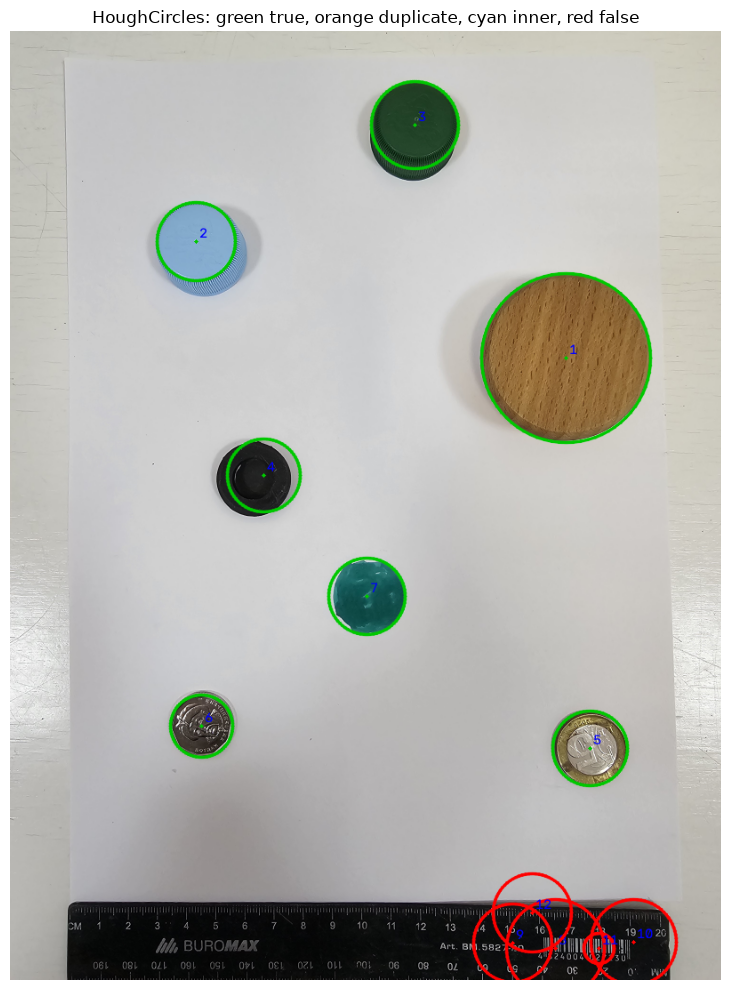

In [16]:
GT_CIRCLES = {   # name: (x, y, r), verified visually on task07_step4_circles.png
    "green_cap":    (455, 105, 49), "blue_cap":   (209, 236, 44), "wood_lid":     (625, 367, 95),
    "black_ring":   (285, 499, 41), "teal_blob":  (401, 635, 43), "small_coin":   (215, 781, 35),
    "bimetal_coin": (652, 806, 42)}
HAS_INNER = {"black_ring", "bimetal_coin"}

def hough_circles(gray_img, dp, minDist, param1, param2, minRadius, maxRadius):
    """Return list of (x, y, r) or []. reshape(-1, 3) handles 4.x (1,N,3) and any 5.0 layout."""
    res = cv2.HoughCircles(gray_img, cv2.HOUGH_GRADIENT, dp=dp, minDist=minDist,
                           param1=param1, param2=param2, minRadius=minRadius, maxRadius=maxRadius)
    return [] if res is None else [tuple(float(v) for v in c) for c in res.reshape(-1, 3)]

def evaluate_circles(circles):
    """Label each detection: true / duplicate / inner / FALSE, by nearest ground-truth centre."""
    labels, found = [], set()
    for x, y, r in circles:
        name, (gx, gy, gr) = min(GT_CIRCLES.items(), key=lambda kv: np.hypot(x - kv[1][0], y - kv[1][1]))
        if np.hypot(x - gx, y - gy) > 0.5 * gr:
            labels.append(("FALSE", "-")); continue
        if abs(r - gr) <= 0.3 * gr:
            labels.append(("duplicate" if name in found else "true", name)); found.add(name)
        elif r < gr and name in HAS_INNER:
            labels.append(("inner", name))
        else:
            labels.append(("FALSE", name))
    return labels, found

CP = dict(dp=1.2, minDist=40, param1=100, param2=30, minRadius=15, maxRadius=110)
circles = hough_circles(gray_med, **CP)
labels, found = evaluate_circles(circles)
print(f"HoughCircles {CP}: {len(circles)} circles")

COLORS = {"true": (0, 200, 0), "duplicate": (0, 165, 255), "inner": (255, 255, 0), "FALSE": (0, 0, 255)}
vis_c4 = img.copy(); rows_c = []
for i, ((x, y, r), (lab, name)) in enumerate(zip(circles, labels), 1):
    c = (int(round(x)), int(round(y)))
    cv2.circle(vis_c4, c, int(round(r)), COLORS[lab], 2, cv2.LINE_AA)
    cv2.circle(vis_c4, c, 2, COLORS[lab], -1)
    cv2.putText(vis_c4, str(i), (c[0] + 4, c[1] - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1, cv2.LINE_AA)
    rows_c.append([i, round(x, 1), round(y, 1), round(r, 1), lab, name])
    print(f"{i:2d}  x={x:6.1f}  y={y:6.1f}  r={r:5.1f}  {lab:9s} {name}")

n = Counter(l for l, _ in labels)
print(f"true {n['true']}/{len(GT_CIRCLES)} | duplicate {n['duplicate']} | inner {n['inner']} | FALSE {n['FALSE']}")
print("missed:", [g for g in GT_CIRCLES if g not in found])

cv2.imwrite(str(RESULTS / "task07_circles.png"), vis_c4)
with open(RESULTS / "task07_circles.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["id", "x", "y", "r", "label", "object"]); w.writerows(rows_c)

plt.figure(figsize=(8, 10)); plt.imshow(cv2.cvtColor(vis_c4, cv2.COLOR_BGR2RGB))
plt.title("HoughCircles: green true, orange duplicate, cyan inner, red false"); plt.axis("off")
plt.tight_layout(); plt.savefig(RESULTS / "task07_step4_circles.png", dpi=120); plt.show()

Step 5: Combined result with coordinates

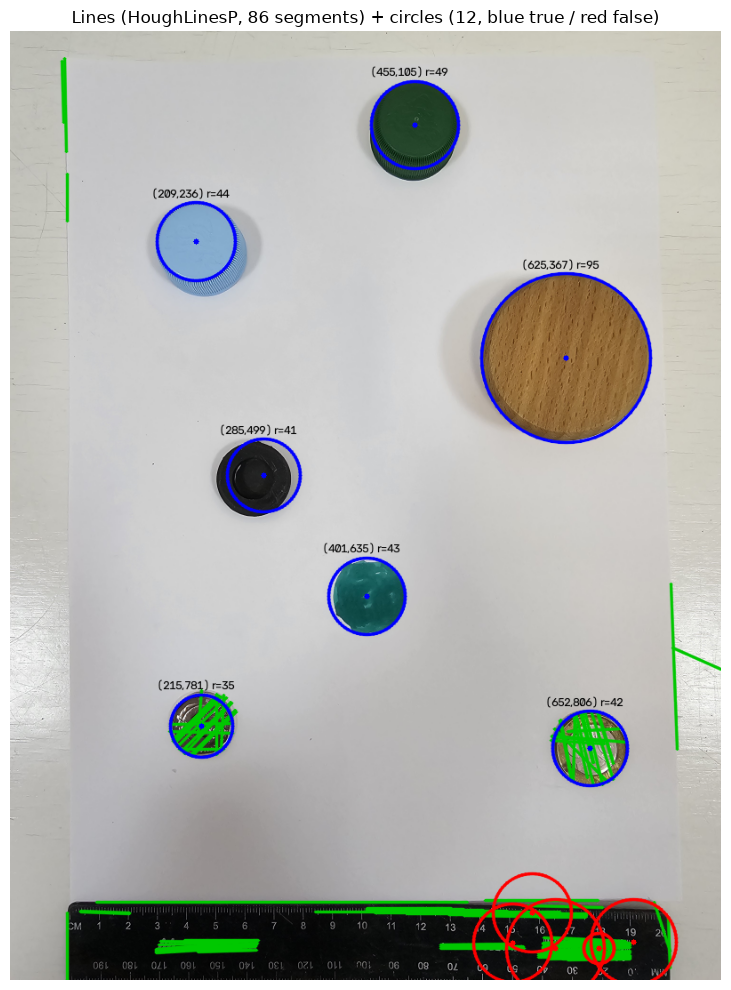

In [17]:
vis_all = img.copy()
for x1, y1, x2, y2 in segs:                                   # HoughLinesP segments
    cv2.line(vis_all, (x1, y1), (x2, y2), (0, 200, 0), 2, cv2.LINE_AA)
for (x, y, r), (lab, name) in zip(circles, labels):            # HoughCircles
    c = (int(round(x)), int(round(y)))
    col = (0, 0, 255) if lab == "FALSE" else (255, 0, 0)
    cv2.circle(vis_all, c, int(round(r)), col, 2, cv2.LINE_AA)
    cv2.circle(vis_all, c, 3, col, -1)
    if lab != "FALSE":                                          # label true circles only (false ones overlap on the ruler)
        cv2.putText(vis_all, f"({c[0]},{c[1]}) r={r:.0f}", (c[0] - 50, c[1] - int(r) - 6),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 1, cv2.LINE_AA)

cv2.imwrite(str(RESULTS / "task07_combined.png"), vis_all)
plt.figure(figsize=(8, 10)); plt.imshow(cv2.cvtColor(vis_all, cv2.COLOR_BGR2RGB))
plt.title(f"Lines (HoughLinesP, {len(segs)} segments) + circles ({len(circles)}, blue true / red false)")
plt.axis("off"); plt.tight_layout(); plt.savefig(RESULTS / "task07_step5_combined.png", dpi=120); plt.show()

Cell 8:

algorithm    param     value |  det  found  dup inner false |     ms
HoughLines   threshold    80 |  128   3/5    17     0   108 |  12.67
HoughLines   threshold   100 |   52   3/5    15     0    34 |  12.99
HoughLines   threshold   150 |    9   3/5     4     0     2 |   9.85
HoughLines   threshold   200 |    1   1/5     0     0     0 |  13.21
HoughLines   threshold   250 |    1   1/5     0     0     0 |  10.55
HoughLinesP  min_len      20 |  147   4/7    38     0   105 |  13.89
HoughLinesP  min_len      50 |   86   4/7    17     0    65 |  35.97
HoughLinesP  min_len     100 |   10   2/7     7     0     1 |  59.91
HoughLinesP  max_gap       5 |   29   4/7     8     0    17 |  36.87
HoughLinesP  max_gap      10 |   86   4/7    17     0    65 |  54.55
HoughLinesP  max_gap      30 |  133   4/7    42     0    87 |  29.35
HoughCircles param2       20 |   27   7/7     0     0    20 |  41.46
HoughCircles param2       30 |   12   7/7     0     0     5 |  34.10
HoughCircles param2       40 |   1

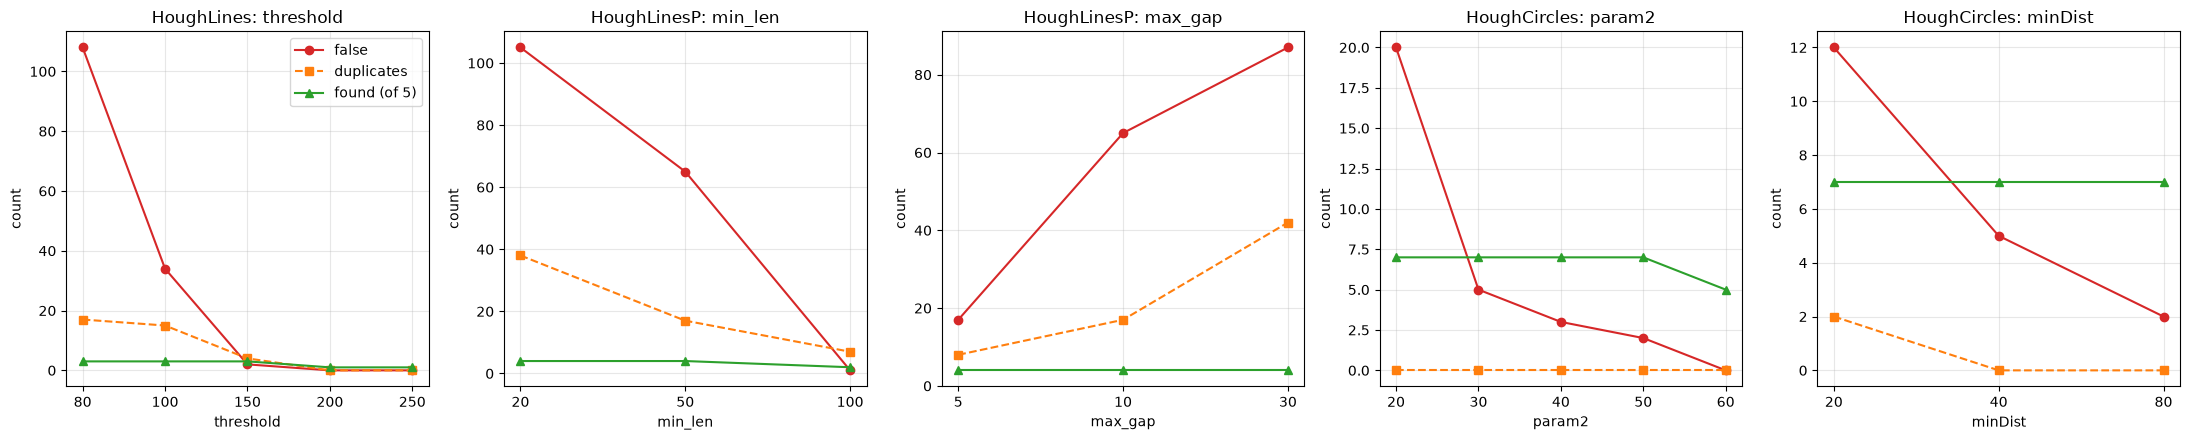

In [18]:
import time

ANG_TOL = 1.5
GT_INF = ["paper_top", "left_edge", "right_edge", "ruler_top", "ruler_bottom"]

def line_category(rho, theta):
    """Classify an infinite (rho, theta) line against the ground truth."""
    deg = np.degrees(theta)
    if rho < 0:                                   # same line written with wrapped angle (179 -> -1 deg)
        rho, deg = -rho, deg - 180
    if abs(deg) < ANG_TOL:                        # vertical
        if rho < 100: return "left_edge"
        if rho > 700: return "right_edge"
    if abs(deg - 90) < ANG_TOL:                   # horizontal
        if rho < 40: return "paper_top"
        if 955 <= rho <= 1005: return "ruler_top"
        if rho >= 1045: return "ruler_bottom"
    return "FALSE"

def timed(fn, *args, reps=5, **kw):
    """Median run time of fn over reps calls (first calls are often slower)."""
    times, out = [], None
    for _ in range(reps):
        t0 = time.perf_counter(); out = fn(*args, **kw); times.append((time.perf_counter() - t0) * 1000)
    return out, float(np.median(times))

def row(alg, param, value, det, on_true, found, gt, false, inner, ms):
    return dict(algorithm=alg, parameter=param, value=value, detections=det, on_true=on_true,
                duplicates=on_true - inner - found, inner=inner, false=false, found=found, gt=gt,
                time_ms=round(ms, 2))

results = []

# A) HoughLines: threshold
for th in [80, 100, 150, 200, 250]:
    L, ms = timed(hough_lines, EDGES, th)
    cats = [line_category(r, t) for r, t in L]
    found = {c for c in cats if c != "FALSE"}; n_true = sum(c != "FALSE" for c in cats)
    results.append(row("HoughLines", "threshold", th, len(L), n_true, len(found), len(GT_INF),
                       len(L) - n_true, 0, ms))

# B) HoughLinesP: minLineLength, maxLineGap
BASE_P = dict(threshold=50, min_len=50, max_gap=10)
for param, values in [("min_len", [20, 50, 100]), ("max_gap", [5, 10, 30])]:
    for v in values:
        kw = dict(BASE_P); kw[param] = v
        S, ms = timed(hough_segments, EDGES, **kw)
        _, _, n_true, n_false, hit = evaluate_segments(S)
        results.append(row("HoughLinesP", param, v, len(S), n_true, len(hit), len(GT_LINES),
                           n_false, 0, ms))

# C) HoughCircles: param2, minDist
for param, values in [("param2", [20, 30, 40, 50, 60]), ("minDist", [20, 40, 80])]:
    for v in values:
        kw = dict(CP); kw[param] = v
        C, ms = timed(hough_circles, gray_med, **kw)
        labs, found = evaluate_circles(C); n = Counter(l for l, _ in labs)
        results.append(row("HoughCircles", param, v, len(C), n["true"] + n["duplicate"] + n["inner"],
                           len(found), len(GT_CIRCLES), n["FALSE"], n["inner"], ms))

print(f"{'algorithm':12s} {'param':9s} {'value':>5s} | {'det':>4s} {'found':>6s} {'dup':>4s} {'inner':>5s} {'false':>5s} | {'ms':>6s}")
for r in results:
    print(f"{r['algorithm']:12s} {r['parameter']:9s} {r['value']:>5} | {r['detections']:4d} "
          f"{r['found']:>3d}/{r['gt']:<2d} {r['duplicates']:4d} {r['inner']:5d} {r['false']:5d} | {r['time_ms']:6.2f}")

with open(RESULTS / "task07_experiment.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(results[0].keys())); w.writeheader(); w.writerows(results)

# plot: one panel per experiment
groups = [("HoughLines", "threshold"), ("HoughLinesP", "min_len"), ("HoughLinesP", "max_gap"),
          ("HoughCircles", "param2"), ("HoughCircles", "minDist")]
fig, ax = plt.subplots(1, 5, figsize=(22, 4.5))
for a, (alg, p) in zip(ax, groups):
    rs = [r for r in results if r["algorithm"] == alg and r["parameter"] == p]
    xs = [str(r["value"]) for r in rs]
    a.plot(xs, [r["false"] for r in rs], "o-", color="tab:red", label="false")
    a.plot(xs, [r["duplicates"] for r in rs], "s--", color="tab:orange", label="duplicates")
    a.plot(xs, [r["found"] for r in rs], "^-", color="tab:green", label=f"found (of {rs[0]['gt']})")
    a.set_title(f"{alg}: {p}"); a.set_xlabel(p); a.set_ylabel("count"); a.grid(alpha=0.3)
ax[0].legend()
plt.tight_layout(); plt.savefig(RESULTS / "task07_experiment.png", dpi=120); plt.show()